**At the start of each notebook there will be 1 - 3 cells of code that need to be run before the rest of the notebook. These cells make sure we have imported all the required Python packages so that we can run the rest of the code without issue!**
- If you do not have these packages, you will need to pip install them. 

In [1]:
import numpy as np # Numpy is used for math and stats in python 
import pandas as pd # Pandas is used for handling data in a spreadsheet like way
import matplotlib.pyplot as plt  # Matplotlib is used for plotting
import seaborn as sns # Seaborn is another plotting package 



In [2]:
## Matt has made a lot of improvements over the last week as we put together this workshop - run this upgrade! Then restart your kernel
#%pip install --upgrade petthermotools

In [3]:
# If the alphaMELTS for Python files have not been added to your Python path (see installation guide) then use the two lines below to add
# the location of the alphaMELTS files here.

# import sys
# sys.path.append(r'C:\Users\penny\Box\Berkeley_new\MELTS_Installation\alphamelts_py\alphamelts-py-2.3.1-win64')


import petthermotools as ptt 

print(ptt.__version__)

alphaMELTS for Python files successfully located.
If you are planning on using the Green et al. (2025) or Weller et al. (2024) thermodynamic models through MAGEMin for crystallization, melting, or phase diagram calculations
you will need to run `ptt.activate_petthermotools_env()` at the start of each notebook, prior to any calculations, every time you restart the kernel. 
This step establishes the python-julia connection and sets up the julia workers. Expect it to take about 20-40s on most machines.
1.3.3


## Lets quickly talk through datatypes
- String are letters and words like  Model = "MELTSv1.2.0" or Model = "pMELTS"
- Dataframes can be though of like an excel sheet - there are columns, with data in them. This data can be a mix of integers (like 3), floats (other numbers, like 3.0, 3.1), and strings (like Volcano Names!)
- Pandas Series are single columns of a dataframe, like one column in an excel spreadsheet
- Dictionaries are sets of data. In PetThermoTools, they are used to return multiple dataframes from a function, like a dataframe of Cpx comps, a dataframe of liquid comps, a dataframe of thermodynaical properties etc. 

# Part 1 - Python basics

First, to get used to data handling in Python, let's load in some data and practice! The following dataset is a compilation of whole-rock data from the Aleutian volcanic arc. We'll use Pandas to import this spreadsheet as a Pandas DataFrame:

In [4]:
Aleu = pd.read_excel("Aleutians.xlsx")
Aleu.head()

,Volcano,SiO2_Liq,TiO2_Liq,Al2O3_Liq,FeOt_Liq,MnO_Liq,MgO_Liq,CaO_Liq,Na2O_Liq,K2O_Liq,P2O5_Liq
0,Augustine,51.821911,0.584089,15.971940,8.038338,0.159048,7.812462,11.044827,2.202869,0.348145,0.110600
1,Augustine,51.821911,0.584089,15.971940,8.038338,0.159048,7.812462,11.044827,2.202869,0.348145,0.110600
2,Augustine,54.254823,0.586529,15.396650,7.798657,0.169585,8.079017,10.791099,2.425790,0.382063,0.115787
3,Augustine,54.254823,0.586529,15.396650,7.798657,0.169585,8.079017,10.791099,2.425790,0.382063,0.115787
4,Augustine,54.038554,0.591405,15.028963,7.897825,0.170651,8.273892,11.172488,2.343959,0.371325,0.110927


You should see that there is a column header called "Volcano". We can investigate which volcanoes we have data for by using the `.unique()` method:

In [5]:
Aleu['Volcano'].unique()

<ArrowStringArray>
['Augustine', 'Shishaldin', 'Okmok']
Length: 3, dtype: str

We can also use the column headers to isolate any of the chemical parameters in a pandas series:

In [6]:
Aleu['SiO2_Liq']

0      51.821911
1      51.821911
2      54.254823
3      54.254823
4      54.038554
         ...    
195    67.330000
196    67.350000
197    71.200000
198    71.330000
199    71.620000
Name: SiO2_Liq, Length: 200, dtype: float64

and we can also use pandas to filter the dataset by volcano, for example we can examine which rows contain "Okmok" in the 'Volcano' column:

In [7]:
Aleu['Volcano'] == "Okmok"

0      False
1      False
2      False
3      False
4      False
       ...  
195     True
196     True
197     True
198     True
199     True
Name: Volcano, Length: 200, dtype: bool

and then use this to filter the main dataset:

In [8]:
Aleu.loc[Aleu['Volcano'] == "Okmok"].reset_index(drop = True)

,Volcano,SiO2_Liq,TiO2_Liq,Al2O3_Liq,FeOt_Liq,MnO_Liq,MgO_Liq,CaO_Liq,Na2O_Liq,K2O_Liq,P2O5_Liq
0,Okmok,50.650000,0.940000,18.460000,7.792210,0.160000,5.840000,12.180000,2.440000,0.520000,0.140000
1,Okmok,51.291326,0.618727,16.315005,8.076539,0.148500,7.957266,11.773530,1.976917,0.704380,0.123358
2,Okmok,51.350000,0.930000,19.220000,7.711229,0.160000,4.640000,11.790000,2.650000,0.560000,0.130000
3,Okmok,51.568859,1.036632,17.512135,9.310603,0.178399,5.043659,10.696818,2.750960,0.641844,0.159841
4,Okmok,52.000000,1.240000,17.000000,9.024927,0.190000,5.150000,10.580000,2.910000,0.720000,0.180000
5,Okmok,52.080000,1.230000,17.110000,9.339855,0.190000,4.770000,10.410000,2.930000,0.740000,0.170000
6,Okmok,52.291430,1.184830,16.930377,9.878605,0.189885,4.688093,9.299109,3.109899,0.881674,0.191586
7,Okmok,52.380000,1.350000,16.010000,10.131673,0.200000,4.930000,9.880000,3.020000,0.790000,0.180000
8,Okmok,52.740000,1.320000,18.050000,8.575031,0.180000,3.850000,10.200000,2.970000,0.950000,0.220000
9,Okmok,52.790000,1.320000,17.770000,8.736993,0.180000,4.010000,10.010000,3.000000,0.980000,0.220000


If we wanted, we could save this filtered dataset as a new variable:

In [9]:
Okmok = Aleu.loc[Aleu['Volcano'] == "Okmok"].reset_index(drop=True)
Okmok.head()

,Volcano,SiO2_Liq,TiO2_Liq,Al2O3_Liq,FeOt_Liq,MnO_Liq,MgO_Liq,CaO_Liq,Na2O_Liq,K2O_Liq,P2O5_Liq
0,Okmok,50.650000,0.940000,18.460000,7.792210,0.160000,5.840000,12.180000,2.440000,0.520000,0.140000
1,Okmok,51.291326,0.618727,16.315005,8.076539,0.148500,7.957266,11.773530,1.976917,0.704380,0.123358
2,Okmok,51.350000,0.930000,19.220000,7.711229,0.160000,4.640000,11.790000,2.650000,0.560000,0.130000
3,Okmok,51.568859,1.036632,17.512135,9.310603,0.178399,5.043659,10.696818,2.750960,0.641844,0.159841
4,Okmok,52.000000,1.240000,17.000000,9.024927,0.190000,5.150000,10.580000,2.910000,0.720000,0.180000


Finally, we can use `matplotlib` alongside  `pandas` to plot up the chemical data from the Aleutian datasets. For example, plotting the data for a single volcano:

Text(0, 0.5, 'FeO$_t$ (wt%)')

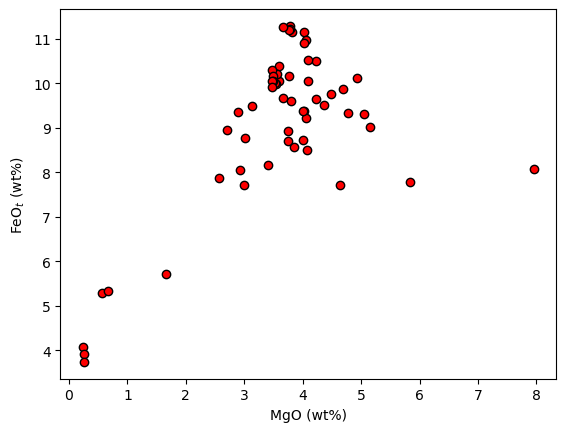

In [10]:
plt.plot(Okmok['MgO_Liq'],
         Okmok['FeOt_Liq'], 'ok', mfc = 'r')
plt.xlabel('MgO (wt%)')
plt.ylabel('FeO$_t$ (wt%)')

Or we could use `subplots` alongside a `for` loop to plot multiple oxides for all volcanoes in the dataset:

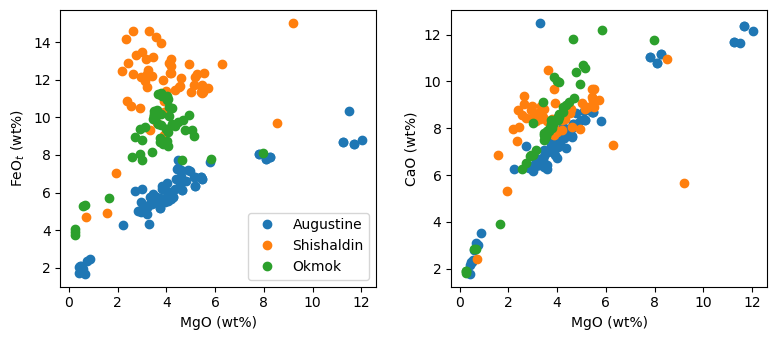

In [11]:
f, a = plt.subplots(1,2, figsize = (8,3.5))
for volc in Aleu['Volcano'].unique():
    df = Aleu.loc[Aleu['Volcano'] == volc].reset_index(drop = True)

    a[0].plot(df['MgO_Liq'], df['FeOt_Liq'], 'o', label = volc)
    a[1].plot(df['MgO_Liq'], df['CaO_Liq'], 'o')

a[0].set_xlabel('MgO (wt%)')
a[1].set_xlabel('MgO (wt%)')

a[0].set_ylabel('FeO$_t$ (wt%)')
a[1].set_ylabel('CaO (wt%)')

a[0].legend()

f.tight_layout()

# Part 2 - Basic calculations

## Finding the liquidus
Time to move onto some MELTS calculations! Many functions in `petthermotools` can use compositions from dataframes, such as that above, as the starting point for thermodynamic calculations. One potentially useful place to start is with finding the liquidus temperature of each sample.

Using the `Okmok` dataframe we created above use the code cell below to calculate the liquidus temperature at a pressure of 2000 bar, test using different water contents to see how these influence the calculated liquidus temperatures if you are waiting for others to finish.

In [12]:
Okmok.head()

,Volcano,SiO2_Liq,TiO2_Liq,Al2O3_Liq,FeOt_Liq,MnO_Liq,MgO_Liq,CaO_Liq,Na2O_Liq,K2O_Liq,P2O5_Liq
0,Okmok,50.650000,0.940000,18.460000,7.792210,0.160000,5.840000,12.180000,2.440000,0.520000,0.140000
1,Okmok,51.291326,0.618727,16.315005,8.076539,0.148500,7.957266,11.773530,1.976917,0.704380,0.123358
2,Okmok,51.350000,0.930000,19.220000,7.711229,0.160000,4.640000,11.790000,2.650000,0.560000,0.130000
3,Okmok,51.568859,1.036632,17.512135,9.310603,0.178399,5.043659,10.696818,2.750960,0.641844,0.159841
4,Okmok,52.000000,1.240000,17.000000,9.024927,0.190000,5.150000,10.580000,2.910000,0.720000,0.180000


In [13]:
liquidus_T = ptt.findLiq_multi(bulk=Okmok,
                               Model="MELTSv1.0.2",
                               P_bar = 2000,
                               fO2_buffer="NNO",
                               fO2_offset=1,
                               H2O_Liq = 2)

findLiq_multi:   0%|          | 0/57 [00:00<?, ?it/s]

findLiq_multi: 57/57 converged, 0 did not (after 1 retry round(s) at +25.0 C and x1.5 timeout each).


In [14]:
liquidus_T.head()

,T_Liq_C,liquidus_phase,fluid_saturated,SiO2_Liq,TiO2_Liq,Al2O3_Liq,Cr2O3_Liq,FeOt_Liq,MnO_Liq,MgO_Liq,CaO_Liq,Na2O_Liq,K2O_Liq,P2O5_Liq,H2O_Liq,CO2_Liq,Fe3Fet_Liq
0,1152.002588,clinopyroxene1,No,50.076914,0.929403,18.253283,0.0,7.703989,0.158220,5.772237,12.040093,2.412812,0.514214,0.138442,2.000393,0.0,0.274840
1,1166.457122,clinopyroxene1,No,50.780652,0.612589,16.153318,0.0,7.996200,0.147031,7.877472,11.655707,1.957352,0.697412,0.122138,2.000130,0.0,0.271045
2,1148.403097,plagioclase1,No,50.760030,0.919525,18.994867,0.0,7.624351,0.158198,4.587739,11.652775,2.619800,0.553677,0.128536,2.000502,0.0,0.273850
3,1136.566237,clinopyroxene1,No,51.101088,1.027290,17.357646,0.0,9.226058,0.176854,4.993869,10.594520,2.727044,0.636287,0.158457,2.000887,0.0,0.268879
4,1137.937376,clinopyroxene1,No,51.478680,1.227647,16.833422,0.0,8.934386,0.188166,5.094630,10.469142,2.881818,0.713049,0.178262,2.000800,0.0,0.272445


## Investigating phase stability

Now that we have a liquidus temperature estimate for each sample we an use another `petthermotools` function to investigate phase stability below the liquidus. `equilibrate_multi` allows us to pass multiple compositions to petthermotools at user specified P-T-H2O-fO2 conditions and calculate the thermodynamic equilibrium. Using the code below equilibriate the Okmok samples at 5, 20, and 50 $^o$C below the liquidus and examine the influence on phase stability:

In [15]:
equil = ptt.equilibrate_multi(Model="MELTSv1.0.2",
                              bulk = Okmok,
                              T_C = liquidus_T['T_Liq_C'].values - 20,
                              P_bar = 2000,
                              H2O_init=2,
                              fO2_buffer="NNO",
                              fO2_offset=1)

equilibrate_multi:   0%|          | 0/57 [00:00<?, ?it/s]

equilibrate_multi: 57/57 succeeded, 0 did not (a timeout is retried once at 2x timeout; a calculation error is not retried).


In [16]:
equil['PhaseList']

0        Liq,Cpx,Plag
1          Liq,Cpx,Ol
2        Liq,Cpx,Plag
3          Liq,Cpx,Sp
4          Liq,Cpx,Sp
5          Liq,Cpx,Sp
6          Liq,Cpx,Sp
7          Liq,Cpx,Sp
8     Liq,Cpx,Plag,Sp
9     Liq,Cpx,Plag,Sp
10    Liq,Cpx,Plag,Sp
11             Liq,Sp
12             Liq,Sp
13             Liq,Sp
14             Liq,Sp
15             Liq,Sp
16             Liq,Sp
17             Liq,Sp
18             Liq,Sp
19             Liq,Sp
20         Liq,Cpx,Sp
21             Liq,Sp
22         Liq,Cpx,Sp
23         Liq,Cpx,Sp
24             Liq,Sp
25             Liq,Sp
26    Liq,Cpx,Plag,Sp
27             Liq,Sp
28             Liq,Sp
29             Liq,Sp
30             Liq,Sp
31             Liq,Sp
32         Liq,Cpx,Sp
33             Liq,Sp
34             Liq,Sp
35             Liq,Sp
36         Liq,Cpx,Sp
37             Liq,Sp
38             Liq,Sp
39             Liq,Sp
40             Liq,Sp
41             Liq,Sp
42         Liq,Cpx,Sp
43             Liq,Sp
44             Liq,Sp
45    Liq,

These equilibrate calculations share a similar output structure to many of the petthermotools calculations, so let's spend some time examining that structure:

# Part 3 - Crystallization Models

Time to move onto some more complex models! One of the most common use of the MELTS models is to simulate magma differentiation, primarily through fractional crystallization. We can use the `help` function to examine the petthermotools `isobaric_crysatllisation` function:

In [17]:
help(ptt.isobaric_crystallisation)

Help on function isobaric_crystallisation in module petthermotools.Path_wrappers:

isobaric_crystallisation(Model=None, bulk=None, Frac_solid=None, Frac_fluid=None, T_path_C=None, T_start_C=None, T_end_C=None, dt_C=None, P_bar=None, Fe3Fet_init=None, Fe3Fet_Liq=None, H2O_init=None, CO2_init=None, H2O_Liq=None, CO2_Liq=None, find_liquidus=False, fO2_buffer=None, fO2_offset=None, label=None, Crystallinity_limit=None, fluid_sat=False, timeout=None, Suppress=['rutile', 'tridymite'], Suppress_except=False, multi_processing=True, quiet_engine=True, MgO_limit=None)
    Simulates isobaric (constant-pressure) crystallization paths using the `multi_path` function.
    
    Parameters
    ----------
    Model : str, optional
        Thermodynamic model, options:
            MELTS:
                "pMELTS"
                "MELTSv1.0.2"
                "MELTSv1.1.0"
                "MELTSv1.2.0"
            MAGEMin:
                "Green2025"
                "Weller2024"
    bulk : dict or pandas.

Before we run any calculations let's first isolate a single starting composition. One possibility is to take the Okmok composition with the highest MgO content as our starting point:

In [18]:
starting_comp = Okmok.loc[Okmok['MgO_Liq'] == np.nanmax(Okmok['MgO_Liq'])].squeeze().to_dict()
starting_comp

{'Volcano': 'Okmok',
 'SiO2_Liq': 51.2913262399805,
 'TiO2_Liq': 0.618726763514556,
 'Al2O3_Liq': 16.3150051698329,
 'FeOt_Liq': 8.076538860466034,
 'MnO_Liq': 0.148499728115197,
 'MgO_Liq': 7.95726593833519,
 'CaO_Liq': 11.7735301035571,
 'Na2O_Liq': 1.97691687346554,
 'K2O_Liq': 0.704380044722205,
 'P2O5_Liq': 0.123358441237645}

In [19]:
frac_xtal = ptt.isobaric_crystallisation(Model="MELTSv1.0.2",
                                         bulk = starting_comp,
                                         P_bar = np.array([1000,2000,4000,6000]),
                                         find_liquidus=True,
                                         dt_C=2,
                                         T_end_C=600,
                                         Frac_solid=True,
                                         Frac_fluid=True,
                                         fO2_buffer="NNO",
                                         fO2_offset=1,
                                         H2O_init = 2,
                                         label = "P_bar")

multi_path_v2: timeout not specified, using the platform default of 60s per path (pass timeout=<seconds> to override).


multi_path_v2:   0%|          | 0/4 [00:00<?, ?it/s]

multi_path_v2: 3/4 completed, 1/4 returned partial results after a crash, 0/4 returned partial results after timing out, 0/4 returned no results (no retry by default -- see max_retries).
  Run 0 (partial results): RuntimeError: path for row 0 stopped early after 235 steps (last step: T = 689.9 C, P = 1000.0 bar) (Path.py, line 775, in _path_task_v2)


Let's examine the output structure again:

In [20]:
frac_xtal['P = 6000.0 bars']['All']['T_C']

0      1232.113731
1      1230.113371
2      1228.113011
3      1226.112651
4      1224.112291
          ...     
312     608.001440
313     606.001080
314     604.000720
315     602.000360
316     600.000000
Name: T_C, Length: 317, dtype: float64

Within petthermotools we've also created several in-built functions for visualizing thermodynamic results. Use the cells below to plot the liquid-line-of-descent using the `harker` function and the phase proportions using the `phase_plot` function:

(<Figure size 960x900 with 9 Axes>,
 array([[<Axes: xlabel='MgO', ylabel='SiO$_2$'>,
         <Axes: xlabel='MgO', ylabel='TiO$_2$'>,
         <Axes: xlabel='MgO', ylabel='Al$_2$O$_3$'>],
        [<Axes: xlabel='MgO', ylabel='FeO$_t$'>,
         <Axes: xlabel='MgO', ylabel='CaO'>,
         <Axes: xlabel='MgO', ylabel='Na$_2$O'>],
        [<Axes: xlabel='MgO', ylabel='K$_2$O'>, <Axes: >, <Axes: >]],
       dtype=object))

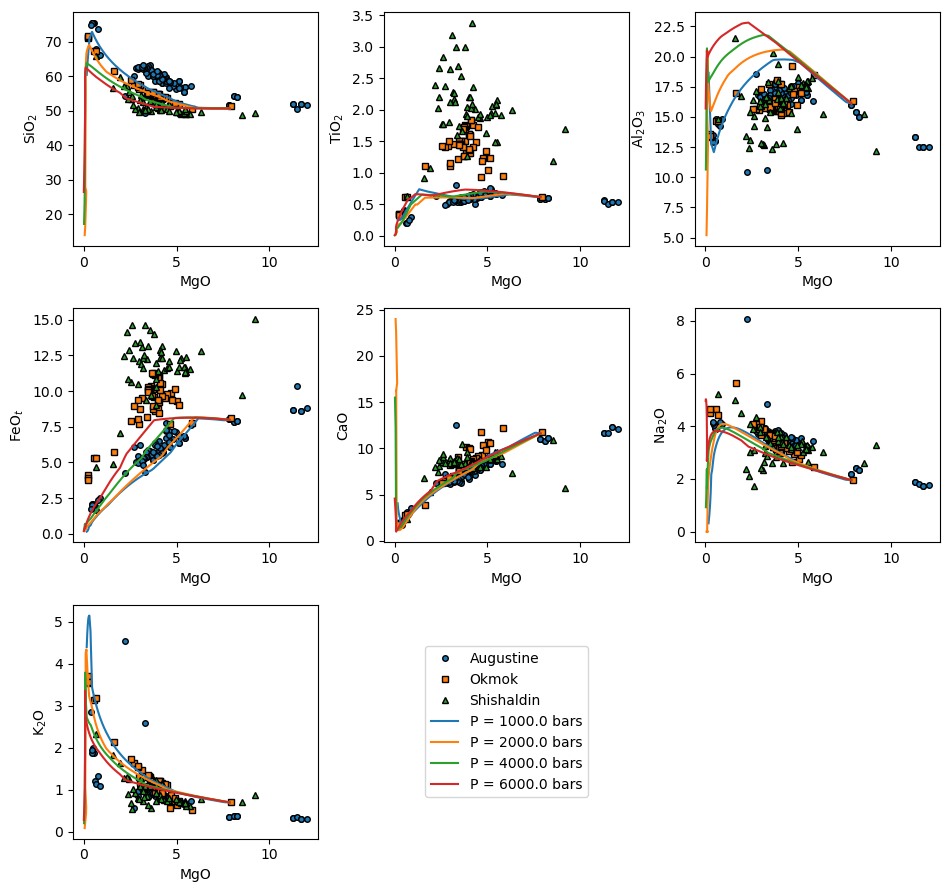

In [21]:
ptt.harker(Results = frac_xtal, 
            data = {"Augustine": Aleu.loc[Aleu['Volcano'] == "Augustine"],
                    "Okmok": Aleu.loc[Aleu['Volcano'] == "Okmok"],
                    "Shishaldin": Aleu.loc[Aleu['Volcano'] == "Shishaldin"],})

(<Figure size 500x350 with 1 Axes>,
 ([<Figure size 500x350 with 1 Axes>,
   <Figure size 500x350 with 1 Axes>,
   <Figure size 500x350 with 1 Axes>,
   <Figure size 500x350 with 1 Axes>],
  [<Axes: title={'center': 'P = 1000.0 bars'}, xlabel='MgO_Liq', ylabel='Mass fraction'>,
   <Axes: title={'center': 'P = 2000.0 bars'}, xlabel='MgO_Liq', ylabel='Mass fraction'>,
   <Axes: title={'center': 'P = 4000.0 bars'}, xlabel='MgO_Liq', ylabel='Mass fraction'>,
   <Axes: title={'center': 'P = 6000.0 bars'}, xlabel='MgO_Liq', ylabel='Mass fraction'>]))

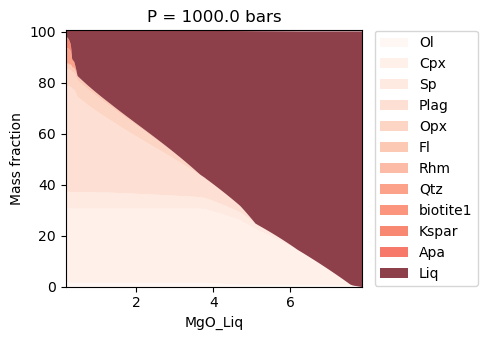

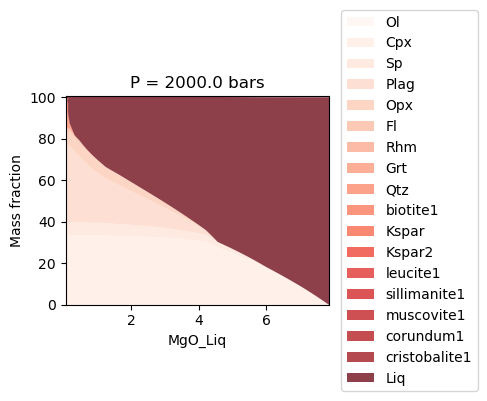

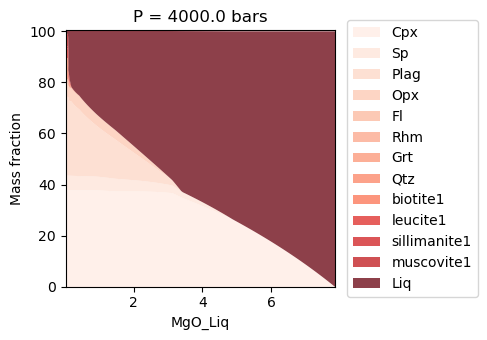

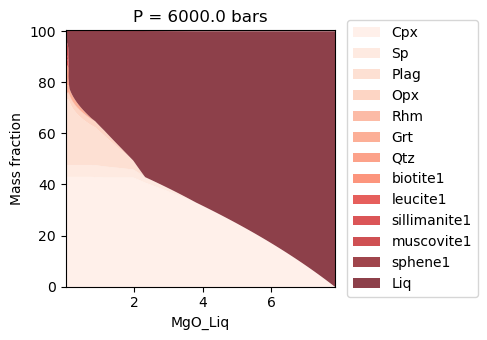

In [22]:
ptt.phase_plot(Results = frac_xtal, x_axis = "MgO_Liq")

(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='MgO_Liq', ylabel='Mass (g) of plagioclase'>)

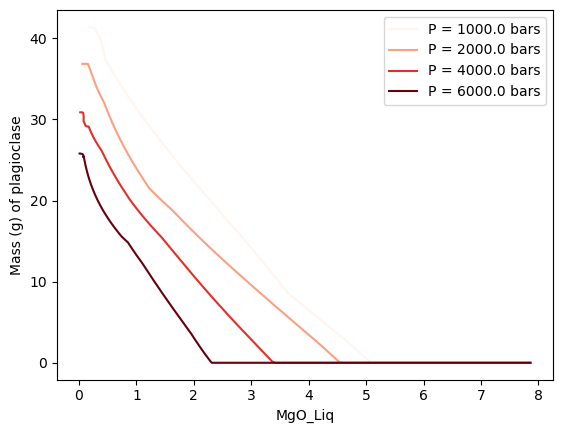

In [23]:
ptt.phase_mass_comparison(Results=frac_xtal, x_axis = "MgO_Liq", phase = "plagioclase1", cmap = "Reds")

# Part 4 - Do some calculations in your own time

Repeat the calculations above, changing the initial water content and/or fO2 instead of pressure. How do these variables influence phase stability. With these melts calculations can you provide any insights into the role of magmatic conditions on the difference between calc-alkaline and tholeiitic differentition trends? Perhaps try plotting SiO2 against FeO/MgO (e.g., https://www.researchgate.net/figure/FeO-MgO-vs-SiO-2-diagram-showing-differences-between-calc-alkaline-Powder-River-Volcanic_fig2_291970605).

In [24]:
frac_xtal_fO2 = ptt.isobaric_crystallisation(Model="MELTSv1.0.2",
                                         bulk = starting_comp,
                                         P_bar = 2000,
                                         find_liquidus=True,
                                         dt_C=2,
                                         T_end_C=600,
                                         Frac_solid=True,
                                         Frac_fluid=True,
                                         fO2_buffer="NNO",
                                         fO2_offset=[-2,-1,0,1,2],
                                         H2O_init = 2,
                                         label = "fO2")

multi_path_v2: timeout not specified, using the platform default of 60s per path (pass timeout=<seconds> to override).


multi_path_v2:   0%|          | 0/5 [00:00<?, ?it/s]

multi_path_v2: 2/5 completed, 3/5 returned partial results after a crash, 0/5 returned partial results after timing out, 0/5 returned no results (no retry by default -- see max_retries).
  Run 0 (partial results): RuntimeError: path for row 0 stopped early after 204 steps (last step: T = 780.0 C, P = 2000.0 bar) (Path.py, line 775, in _path_task_v2)
  Run 1 (partial results): RuntimeError: path for row 1 stopped early after 213 steps (last step: T = 757.9 C, P = 2000.0 bar) (Path.py, line 775, in _path_task_v2)
  Run 2 (partial results): RuntimeError: path for row 2 stopped early after 251 steps (last step: T = 676.0 C, P = 2000.0 bar) (Path.py, line 775, in _path_task_v2)


(<Figure size 960x900 with 9 Axes>,
 array([[<Axes: xlabel='MgO', ylabel='SiO$_2$'>,
         <Axes: xlabel='MgO', ylabel='TiO$_2$'>,
         <Axes: xlabel='MgO', ylabel='Al$_2$O$_3$'>],
        [<Axes: xlabel='MgO', ylabel='FeO$_t$'>,
         <Axes: xlabel='MgO', ylabel='CaO'>,
         <Axes: xlabel='MgO', ylabel='Na$_2$O'>],
        [<Axes: xlabel='MgO', ylabel='K$_2$O'>, <Axes: >, <Axes: >]],
       dtype=object))

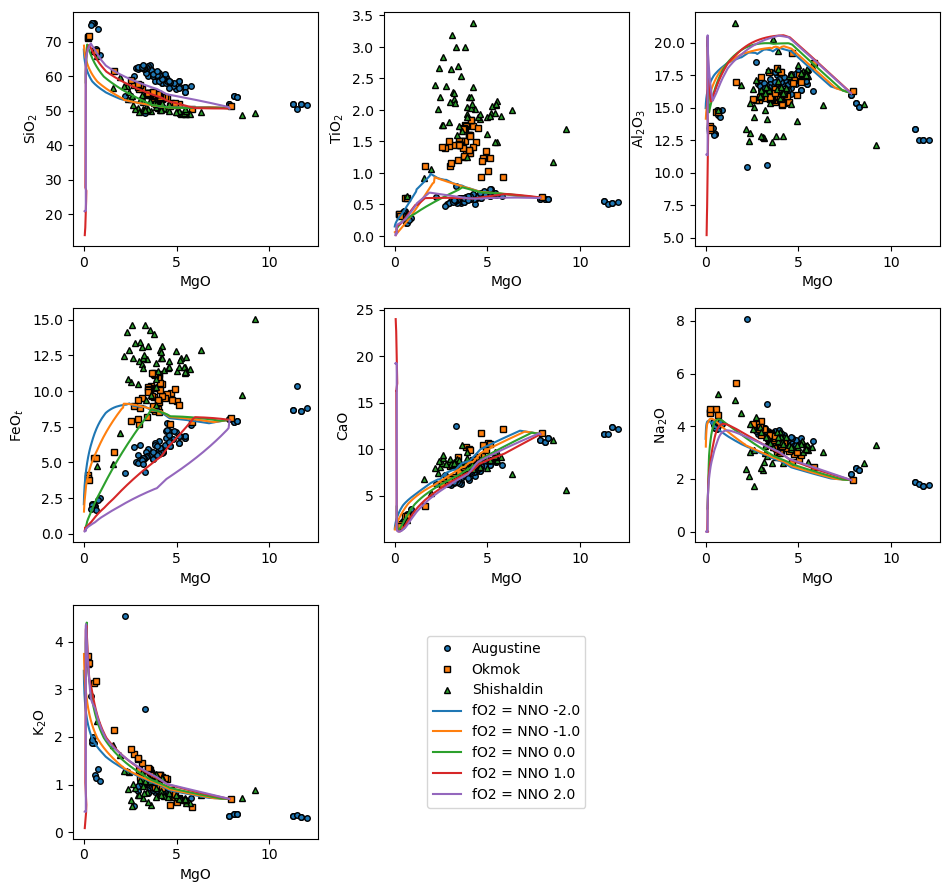

In [25]:
ptt.harker(Results = frac_xtal_fO2, 
            data = {"Augustine": Aleu.loc[Aleu['Volcano'] == "Augustine"],
                    "Okmok": Aleu.loc[Aleu['Volcano'] == "Okmok"],
                    "Shishaldin": Aleu.loc[Aleu['Volcano'] == "Shishaldin"],})